# Gamma-scan re-plotting

Regenerates the main plots of a `gamma_scan.py` run from its saved outputs
(no pipeline imports needed — everything is read from the run directory):

1. **Final scan plot** — recovered $\gamma$ vs true $\gamma$ with residuals.
2. **Posteriors overlay** for one $\gamma$ point — all bootstrap posteriors,
   the combined (mixture) posterior, the prior, and the truth.
3. **Corner plot** for any single $(\gamma\ \mathrm{point},\ \mathrm{bootstrap})$ fit.

Set `RUN_DIR` below to any run directory, or leave it `None` to use the
most recent run in `../scripts/gamma_scan_outputs/`.

In [1]:
import glob
import json
import os

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde, norm

OUTPUTS_ROOT = "../scripts/gamma_scan_outputs"

# Run directory: explicit path, or None for the latest run_* in OUTPUTS_ROOT
RUN_DIR = None

if RUN_DIR is None:
    candidates = sorted(glob.glob(os.path.join(OUTPUTS_ROOT, "run_*")))
    if not candidates:
        raise FileNotFoundError(f"no run_* directories in {OUTPUTS_ROOT}")
    RUN_DIR = candidates[-1]
print(f"run directory: {RUN_DIR}")

# Gamma prior used by gamma_scan.py (hard-coded there; needed for the overlay)
GAMMA_PRIOR = norm(loc=0.0, scale=3.5)

PARAM_LABELS = {
    "c0": r"$c_0$", "alpha": r"$\alpha$", "beta": r"$\beta$",
    "gamma": r"$\gamma$", "log_M_norm": r"$\log M_{\rm norm}$",
}

run directory: ../scripts/gamma_scan_outputs/run_2026-07-11T16-01-09


In [2]:
def _wq(v, w, q):
    """Weighted quantile."""
    order = np.argsort(v)
    v, w = np.asarray(v)[order], np.asarray(w)[order]
    cw = np.cumsum(w)
    return float(np.interp(q * cw[-1], cw, v))


def load_gamma_dirs(run_dir):
    """Sorted list of (g_idx, gamma_true, path) for the run's gamma points."""
    out = []
    for d in sorted(glob.glob(os.path.join(run_dir, "simulation_g*"))):
        ens_path = os.path.join(d, "ensemble_summary.json")
        if not os.path.exists(ens_path):
            continue
        ens = json.load(open(ens_path))
        out.append((ens["g_idx"], ens["gamma_true"], d))
    return out


def load_ensemble(run_dir):
    """Per-gamma ensemble results, tolerant of old/new key names."""
    rows = []
    for g_idx, gamma_true, d in load_gamma_dirs(run_dir):
        ens = json.load(open(os.path.join(d, "ensemble_summary.json")))
        sigma = ens.get("sigma_gamma", ens.get("sigma_boot", np.nan))
        rows.append({
            "g_idx": g_idx,
            "gamma_true": gamma_true,
            "gamma_est": ens["gamma_ensemble_med"],
            "sigma": sigma,
            "n_bootstrap": ens.get("n_bootstrap", None),
            "dir": d,
        })
    return rows


def load_bootstraps(gamma_dir):
    """List of per-bootstrap dicts with summary and posterior samples."""
    out = []
    for d in sorted(glob.glob(os.path.join(gamma_dir, "bootstrap_*"))):
        s_path = os.path.join(d, "summary.json")
        p_path = os.path.join(d, "gamma_posterior.npz")
        if not (os.path.exists(s_path) and os.path.exists(p_path)):
            continue
        rec = json.load(open(s_path))
        rec["npz"] = p_path
        out.append(rec)
    return out


ensemble = load_ensemble(RUN_DIR)
n_clusters = None
if ensemble:
    boots0 = load_bootstraps(ensemble[0]["dir"])
    if boots0:
        n_clusters = boots0[0].get("n_clusters")
print(f"{len(ensemble)} gamma points, N_clusters={n_clusters}")
for r in ensemble:
    print(f"  g{r['g_idx']:02d}: gamma_true={r['gamma_true']:+.2f}  "
          f"gamma_est={r['gamma_est']:+.4f} +- {r['sigma']:.4f}  "
          f"(N_boot={r['n_bootstrap']})")

11 gamma points, N_clusters=15000
  g00: gamma_true=-0.50  gamma_est=-0.4486 +- 0.0849  (N_boot=50)
  g01: gamma_true=-0.35  gamma_est=+0.1005 +- 0.7886  (N_boot=50)
  g02: gamma_true=-0.20  gamma_est=+1.2351 +- 0.1549  (N_boot=50)
  g03: gamma_true=-0.05  gamma_est=-0.1613 +- 0.3819  (N_boot=50)
  g04: gamma_true=+0.10  gamma_est=-0.6651 +- 0.5589  (N_boot=50)
  g05: gamma_true=+0.25  gamma_est=+1.4953 +- 0.6563  (N_boot=50)
  g06: gamma_true=+0.40  gamma_est=+0.6511 +- 0.5819  (N_boot=50)
  g07: gamma_true=+0.55  gamma_est=-0.2473 +- 0.9620  (N_boot=50)
  g08: gamma_true=+0.70  gamma_est=+0.2268 +- 0.7415  (N_boot=50)
  g09: gamma_true=+0.85  gamma_est=+0.7985 +- 0.1420  (N_boot=50)
  g10: gamma_true=+1.00  gamma_est=-0.1025 +- 0.9898  (N_boot=50)


## 1. Final scan plot — $\gamma_{\rm est}$ vs $\gamma_{\rm true}$

RMS bias = 0.7719   mean sigma = 0.5493


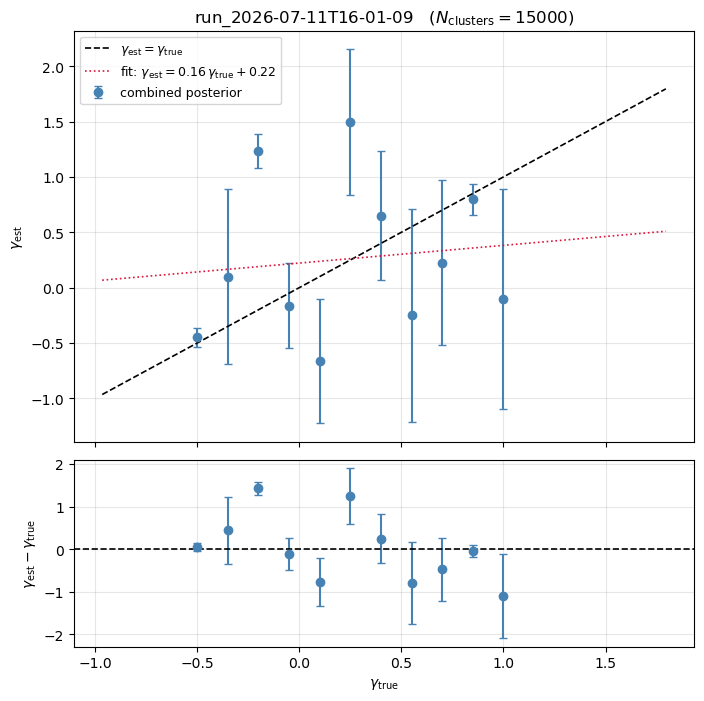

In [3]:
g_t = np.array([r["gamma_true"] for r in ensemble])
g_e = np.array([r["gamma_est"]  for r in ensemble])
s_g = np.array([r["sigma"]      for r in ensemble])
res = g_e - g_t

# Linear fit gamma_est = a * gamma_true + b
A = np.column_stack([g_t, np.ones_like(g_t)])
(a_fit, b_fit), *_ = np.linalg.lstsq(A, g_e, rcond=None)

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 8), sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1.0], "hspace": 0.06},
)
ax1.errorbar(g_t, g_e, yerr=s_g, fmt="o", ms=6, capsize=3,
             color="steelblue", ecolor="steelblue", label="combined posterior")
lim = [min(g_t.min(), g_e.min()) - 0.3, max(g_t.max(), g_e.max()) + 0.3]
ax1.plot(lim, lim, "k--", lw=1.2, label=r"$\gamma_{\rm est}=\gamma_{\rm true}$")
xg = np.linspace(lim[0], lim[1], 10)
ax1.plot(xg, a_fit * xg + b_fit, color="crimson", lw=1.2, ls=":",
         label=rf"fit: $\gamma_{{\rm est}}={a_fit:.2f}\,\gamma_{{\rm true}}{b_fit:+.2f}$")
ax1.set_ylabel(r"$\gamma_{\rm est}$")
ax1.set_title(f"{os.path.basename(RUN_DIR)}   ($N_{{\\rm clusters}}={n_clusters}$)")
ax1.legend(fontsize=9)
ax1.grid(alpha=0.3)

ax2.errorbar(g_t, res, yerr=s_g, fmt="o", ms=6, capsize=3, color="steelblue")
ax2.axhline(0.0, color="k", ls="--", lw=1.2)
ax2.set_xlabel(r"$\gamma_{\rm true}$")
ax2.set_ylabel(r"$\gamma_{\rm est}-\gamma_{\rm true}$")
ax2.grid(alpha=0.3)

print(f"RMS bias = {np.sqrt(np.mean(res**2)):.4f}   "
      f"mean sigma = {np.mean(s_g):.4f}")
plt.show()

## 2. Posteriors overlay for one $\gamma$ point

Set `OVERLAY_G_IDX` to the gamma point you want (see the list printed above).

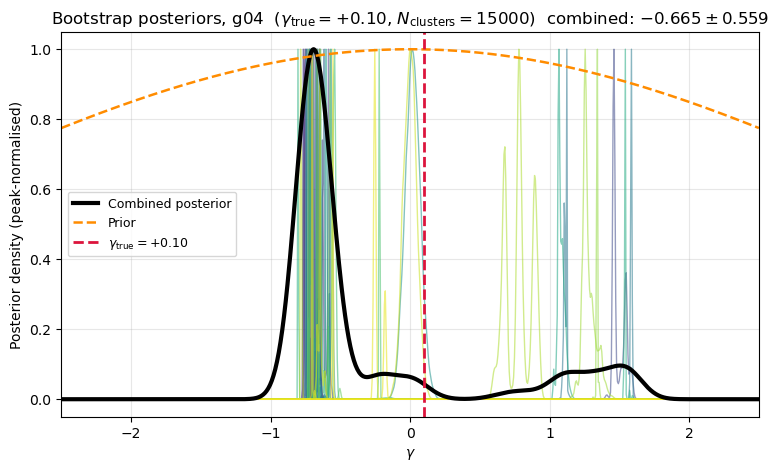

In [7]:
OVERLAY_G_IDX = 4

row = next(r for r in ensemble if r["g_idx"] == OVERLAY_G_IDX)
boots = load_bootstraps(row["dir"])

fig, ax = plt.subplots(figsize=(9, 5))
x_grid = np.linspace(-2.5, 2.5, 800)
cmap = plt.cm.viridis
pool_s, pool_w = [], []
for k, b in enumerate(boots):
    data = np.load(b["npz"])
    samples, weights = data["gamma_samples"], data["weights"]
    pool_s.append(samples)
    pool_w.append(weights / weights.sum())
    try:
        kde = gaussian_kde(samples, weights=weights, bw_method=0.15)
        y = kde(x_grid)
        # Peak-normalise every curve: narrow per-fit posteriors would
        # otherwise dwarf the broad combined mixture on a density scale.
        ax.plot(x_grid, y / y.max(),
                color=cmap(k / max(len(boots) - 1, 1)), alpha=0.55, lw=1.0)
    except Exception:
        pass

pool_s_c = np.concatenate(pool_s)
pool_w_c = np.concatenate(pool_w)
pool_w_c = pool_w_c / pool_w_c.sum()
kde_comb = gaussian_kde(pool_s_c, weights=pool_w_c, bw_method=0.15)
y_comb = kde_comb(x_grid)
ax.plot(x_grid, y_comb / y_comb.max(), color="black", lw=3.0,
        label="Combined posterior")

comb_med = _wq(pool_s_c, pool_w_c, 0.50)
comb_sig = (_wq(pool_s_c, pool_w_c, 0.84) - _wq(pool_s_c, pool_w_c, 0.16)) / 2

y_prior = GAMMA_PRIOR.pdf(x_grid)
ax.plot(x_grid, y_prior / y_prior.max(), color="darkorange", lw=1.8, ls="--",
        label="Prior")
ax.axvline(row["gamma_true"], color="crimson", lw=2.0, ls="--",
           label=rf"$\gamma_{{\rm true}}={row['gamma_true']:+.2f}$")
ax.set(xlabel=r"$\gamma$", ylabel="Posterior density (peak-normalised)",
       title=(rf"Bootstrap posteriors, g{OVERLAY_G_IDX:02d}  "
              rf"($\gamma_{{\rm true}}={row['gamma_true']:+.2f}$, "
              rf"$N_{{\rm clusters}}={n_clusters}$)  "
              rf"combined: ${comb_med:+.3f}\pm{comb_sig:.3f}$"))
ax.set_xlim(x_grid[0], x_grid[-1])
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.show()

## 3. Corner plot for a single $(\gamma\ \mathrm{point},\ \mathrm{bootstrap})$ fit

Set `CORNER_G_IDX` and `CORNER_B_IDX`. Truth lines: crimson = true values
(OLS-fit coefficients of the truth catalogue for $c_0,\alpha,\beta$;
the input $\gamma_{\rm true}$ for $\gamma$).

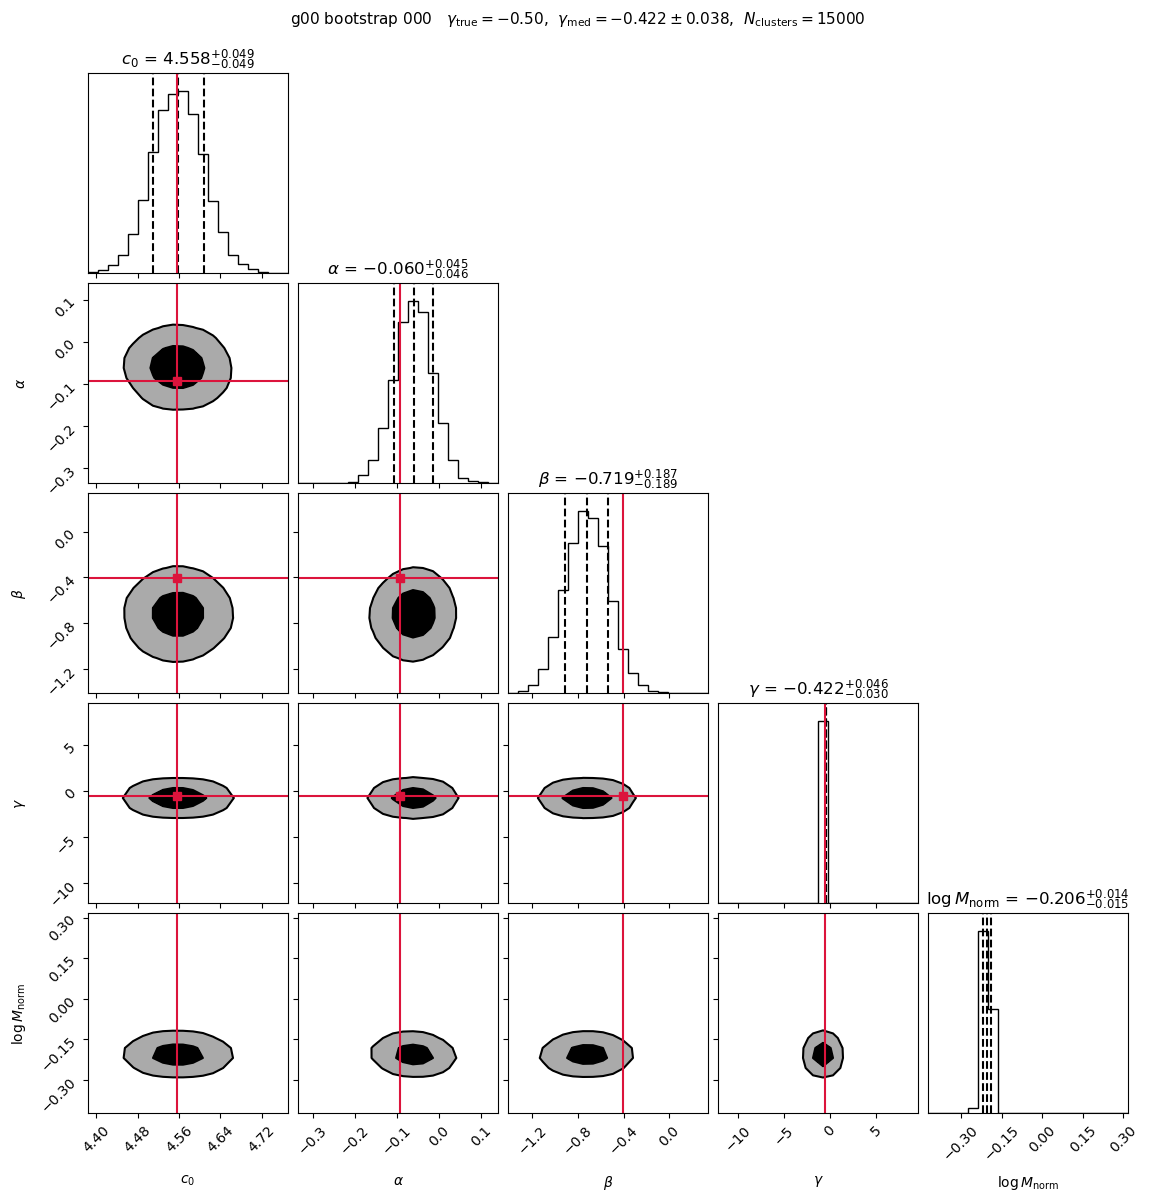

In [5]:
import corner

CORNER_G_IDX = 0
CORNER_B_IDX = 0

row = next(r for r in ensemble if r["g_idx"] == CORNER_G_IDX)
npz_path = os.path.join(row["dir"], f"bootstrap_{CORNER_B_IDX:03d}",
                        "gamma_posterior.npz")
summ_path = os.path.join(row["dir"], f"bootstrap_{CORNER_B_IDX:03d}",
                         "summary.json")
data = np.load(npz_path, allow_pickle=True)
summ = json.load(open(summ_path))

points = data["all_samples"]
weights = data["weights"]
param_order = [str(p) for p in data["param_order"]]
labels = [PARAM_LABELS.get(p, p) for p in param_order]

ols = {}
ols_path = os.path.join(row["dir"], "ols.json")
if os.path.exists(ols_path):
    ols = json.load(open(ols_path))
truth_map = {
    "gamma": row["gamma_true"],
    "c0":    ols.get("c0_true", summ.get("c0_true")),
    "alpha": ols.get("alpha_true", summ.get("alpha_true")),
    "beta":  ols.get("beta_true", summ.get("beta_true")),
}
truths = [truth_map.get(p) for p in param_order]

fig = corner.corner(
    points, weights=weights,
    labels=labels, truths=truths, truth_color="crimson",
    quantiles=[0.16, 0.50, 0.84],
    show_titles=True, title_fmt=".3f",
    plot_datapoints=False, fill_contours=True,
    levels=(0.39, 0.86), smooth=1.0,
)
fig.suptitle(
    (f"g{CORNER_G_IDX:02d} bootstrap {CORNER_B_IDX:03d}   "
     rf"$\gamma_{{\rm true}}={row['gamma_true']:+.2f}$,  "
     rf"$\gamma_{{\rm med}}={summ['gamma_med']:+.3f}\pm{summ['sigma_gamma']:.3f}$,  "
     rf"$N_{{\rm clusters}}={summ.get('n_clusters')}$"),
    y=1.02, fontsize=11,
)
plt.show()